# Transition-case prevalence analysis

Question: is the **middle hyperedge-bias case** more prevalent in a high-homogeneity dataset (`email-Eu-full`)?

This notebook simulates HMRW-style walks and, at each step, counts how many candidate hyperedges fall into:

- first case: same previous hyperedge (`e' == e_prev`)
- middle case: shares another node with previous hyperedge (excluding current node)
- third case: neither of the above

Counts are aggregated across all start nodes and all walks.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from hypergraphx import Hypergraph

from itertools import combinations
import pickle

In [ ]:
def load_txt(path: str | Path) -> Hypergraph:
    edges = []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            edges.append([int(x) for x in line.replace(",", " ").split()])
    return Hypergraph(edges)

In [89]:
def analyze_transition_cases_with_selection(
    H: Hypergraph,
    *,
    walk_length: int = 40,
    num_walks: int = 10,
    p: float = 1.0,
    q: float = 1.0,
    r: float = 1.0,
    gamma: float = -1.0,
    delta: float = 0.0,
    seed: int = 0,
) -> dict:
    """Return selection and availability case counts for one (p, q) run."""
    nodes = sorted(H.get_nodes())
    edges = [frozenset(e) for e in H.get_edges()]
    n = len(nodes)

    idx = {u: i for i, u in enumerate(nodes)}
    inc_edges = [[] for _ in range(n)]
    d = np.zeros(n, dtype=float)

    for e_i, e in enumerate(edges):
        for u in e:
            i = idx[u]
            inc_edges[i].append(e_i)
            d[i] += 1.0

    selected_counts = {"first": 0, "middle": 0, "third": 0}
    available_counts = {"first": 0, "middle": 0, "third": 0}

    rng = np.random.default_rng(seed)

    for _ in range(num_walks):
        for start in rng.permutation(n):
            v_i = int(start)
            prev_u_i = None
            prev_e_i = None

            for _step in range(walk_length - 1):
                cand_e = inc_edges[v_i]
                if not cand_e:
                    continue

                def classify_case(e2_i: int) -> str:
                    if prev_e_i is None or prev_u_i is None:
                        return "middle"
                    if e2_i == prev_e_i:
                        return "first"
                    v_node = nodes[v_i]
                    if len((edges[prev_e_i] - {v_node}) & (edges[e2_i] - {v_node})) > 0:
                        return "middle"
                    return "third"

                # Availability counts over all candidates at this step.
                for e2_i in cand_e:
                    available_counts[classify_case(e2_i)] += 1

                # Stage 1 sample next hyperedge.
                raw_e = np.zeros(len(cand_e), dtype=float)
                for k, e2_i in enumerate(cand_e):
                    e2 = edges[e2_i]
                    if prev_e_i is None or prev_u_i is None:
                        a_edge = 1.0
                    elif e2_i == prev_e_i:
                        a_edge = 1.0 / p
                    elif len((edges[prev_e_i] - {nodes[v_i]}) & (e2 - {nodes[v_i]})) > 0:
                        a_edge = 1.0
                    else:
                        a_edge = 1.0 / q
                    size_term = max(len(e2) - 1, 1)
                    raw_e[k] = a_edge * (size_term ** gamma)

                s_e = raw_e.sum()
                if s_e <= 0 or not np.isfinite(s_e):
                    next_e_i = int(rng.choice(cand_e))
                else:
                    next_e_i = cand_e[int(rng.choice(len(cand_e), p=raw_e / s_e))]

                # Selection count for chosen hyperedge.
                selected_counts[classify_case(next_e_i)] += 1

                # Stage 2 sample next node.
                e2 = edges[next_e_i]
                cand_x = [idx[x] for x in e2 if idx[x] != v_i]
                if not cand_x:
                    continue

                raw_x = np.zeros(len(cand_x), dtype=float)
                prev_e_nodes = edges[prev_e_i] if prev_e_i is not None else None
                for k, x_i in enumerate(cand_x):
                    if prev_u_i is None:
                        a_node = 1.0
                    elif prev_e_nodes is not None and nodes[x_i] in prev_e_nodes:
                        a_node = 1.0
                    else:
                        a_node = 1.0 / r
                    raw_x[k] = a_node * (max(float(d[x_i]), 1.0) ** delta)

                s_x = raw_x.sum()
                if s_x <= 0 or not np.isfinite(s_x):
                    x_i = int(rng.choice(cand_x))
                else:
                    x_i = cand_x[int(rng.choice(len(cand_x), p=raw_x / s_x))]

                prev_u_i = v_i
                prev_e_i = next_e_i
                v_i = x_i

    return {
        "selected": selected_counts,
        "available": available_counts,
    }

## Disjointness vs Availability

In [ ]:
# Compare empirical availability vs theoretical values for both datasets.

def theoretical_case_values(H: Hypergraph) -> np.ndarray:
    degsum = 0.0
    for deg, cnt in H.degree_distribution().items():
        degsum += deg * cnt
    avgdeg = degsum / H.num_nodes()

    avghedgesize = float(np.mean(H.get_sizes()))
    hom = float(np.mean(hyperedge_homogeneity_list(H)))

    same = 1.0 / avgdeg
    middle = (avghedgesize - 1.0) * (hom - 1.0) / avgdeg
    other = 1.0 - same - middle
    return np.array([same, middle, other], dtype=float)


def empirical_availability_values(H: Hypergraph, seed: int = 42) -> np.ndarray:
    out = analyze_transition_cases_with_selection(
        H,
        walk_length=20,
        num_walks=50,
        p=1.0,
        q=1.0,
        r=1.0,
        gamma=0.0,
        delta=0.0,
        seed=seed,
    )
    labels = ["first", "middle", "third"]
    av = np.array([out["available"][k] for k in labels], dtype=float)
    return av / max(av.sum(), 1.0)

def hypergraph_disjointness(H):
    edges = [set(e) for e in H.get_edges()]

    overlapping = 0
    total = 0
    for i, e1 in enumerate(edges):
        for j, e2 in enumerate(edges):
            if i >= j:
                continue
            total += 1
            if len(e1 & e2) > 1:
                overlapping += 1

    disjointness_violation = overlapping / total
    
    return disjointness_violation

def hyperedge_homogeneity_list(H):
    edges = [list(e) for e in H.get_edges()]

    # pair_degree[(u, v)] = how many hyperedges contain that pair
    pair_degree = {}
    for edge in edges:
        for u, v in combinations(sorted(edge), 2):
            pair_degree[(u, v)] = pair_degree.get((u, v), 0) + 1

    homogeneity = []
    for edge in edges:
        if len(edge) <= 1:
            homogeneity.append(0.0)
            continue

        pair_values = []
        for u, v in combinations(sorted(edge), 2):
            pair_values.append(pair_degree[(u, v)])

        homogeneity.append(sum(pair_values) / len(pair_values))

    return homogeneity

In [132]:
# Dataset list (the two datasets used above).
dataset_names = ["contact-primary", "contact-high",
            "email-Enron-full", "email-Eu-full",]
            # "NDC-classes-full", "NDC-substances-full"]

datasets = {}
for name in dataset_names:
    print(name)
    DATA_PATH = Path(f"../www21-hyperlap-master/dataset/{name}_graph.txt")
    H = load_txt(DATA_PATH)
    empirical = empirical_availability_values(H, seed=42 + i)
    theoretical = theoretical_case_values(H)
    homogeneity = hyperedge_homogeneity_list(H),
    disjointness = hypergraph_disjointness(H)
    
    datasets[name] = {
        "H": H,
        "empirical": empirical,
        "theoretical": theoretical,
        "homogeneity_mean": np.mean(homogeneity),
        "homogeneity": homogeneity,
        "disjointness": disjointness,
        }

contact-primary
contact-high
email-Enron-full
email-Eu-full


Saved: results/images/real_datasets_transition_cases_empirical_vs_theoretical.png


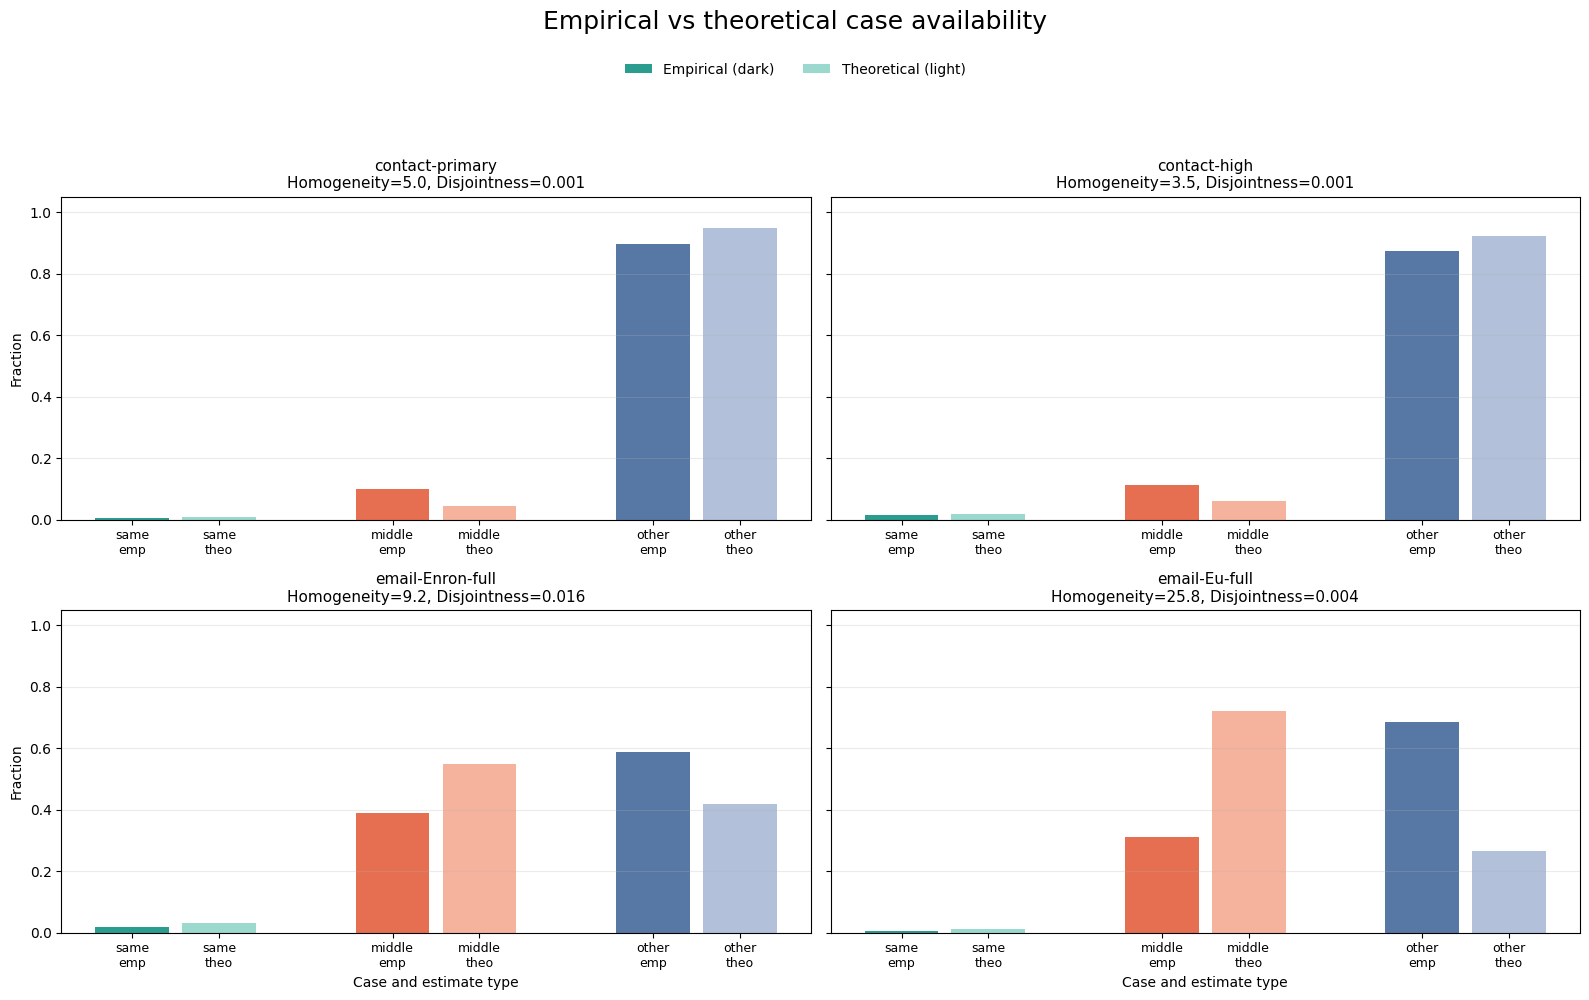

In [139]:
first_four = dataset_names[:4]

case_labels = ["same", "middle", "other"]
emp_colors = ["#2a9d8f", "#e76f51", "#5778a4"]
theo_colors = ["#9bd9cf", "#f5b39d", "#b2c0d9"]

fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharey=True)
axes = axes.flatten()

for ax, name in zip(axes, first_four):
    values = datasets[name]
    empirical = np.asarray(values["empirical"], dtype=float)
    theoretical = np.asarray(values["theoretical"], dtype=float)

    hm = values.get("homogeneity_mean", np.nan)
    try:
        hm = float(np.asarray(hm).reshape(-1)[0])
    except Exception:
        hm = float(np.nan)

    dj = float(values.get("disjointness", np.nan))

    x = np.array([0, 1, 3, 4, 6, 7], dtype=float)
    heights = np.array([
        empirical[0], theoretical[0],
        empirical[1], theoretical[1],
        empirical[2], theoretical[2],
    ])
    colors = [
        emp_colors[0], theo_colors[0],
        emp_colors[1], theo_colors[1],
        emp_colors[2], theo_colors[2],
    ]

    ax.bar(x, heights, color=colors, width=0.85)
    ax.set_xticks(x)
    ax.set_xticklabels(
        [
            "same\nemp", "same\ntheo",
            "middle\nemp", "middle\ntheo",
            "other\nemp", "other\ntheo",
        ],
        fontsize=9,
    )
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", alpha=0.25)
    ax.set_title(f"{name}\nHomogeneity={hm:.1f}, Disjointness={dj:.3f}", fontsize=11)

for ax in axes[2:]:
    ax.set_xlabel("Case and estimate type")
for ax in axes[::2]:
    ax.set_ylabel("Fraction")

from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor="#2a9d8f", label="Empirical (dark)"),
    Patch(facecolor="#9bd9cf", label="Theoretical (light)"),
]
fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.955),
    ncol=2,
    frameon=False,
)

fig.suptitle("Empirical vs theoretical case availability", fontsize=18, y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.90])

out_dir = Path("results/images")
out_path = out_dir / "real_datasets_transition_cases_empirical_vs_theoretical.png"
fig.savefig(out_path, dpi=300, bbox_inches="tight", pad_inches=0.25)
print(f"Saved: {out_path}")

plt.show()